# CliffWalking-v1 using SARSA
**Eman Fayyaz | FA23-BAI-030**

Topics in AI - Assignment 1

A from-scratch on-policy reinforcement learning agent. Run this notebook from the project folder after installing requirements.txt. All nine training experiments are executed below.

In [1]:
import gymnasium as gym
import numpy as np
from utils import make_env
print("Gymnasium:", gym.__version__)
env=make_env()
print("States:",env.observation_space.n,"Actions:",env.action_space.n)
print("Start:",env.reset(seed=30)[0])
env.close()

Gymnasium: 1.2.3
States: 48 Actions: 4
Start: 36


## SARSA update
Q(s,a) ← Q(s,a) + α [r + γ Q(s′,a′) − Q(s,a)].

The next action a′ is selected by the same epsilon-greedy policy and carried into the next step. At true termination the target is r. Falling into the cliff costs -100 and returns the agent to the start without terminating. A 500-step wrapper prevents endless episodes.

In [2]:
from main import run_experiments
summary=run_experiments()


Training epsilon=0.01, seed=30
Episode  500 | train return (last 100):  -19.10 | validation return:  -48.56
Episode 1000 | train return (last 100):  -18.55 | validation return:  -26.42
Episode 1500 | train return (last 100):  -22.32 | validation return:  -22.94
Episode 2000 | train return (last 100):  -17.36 | validation return:  -24.27
Episode 2500 | train return (last 100):  -17.34 | validation return:  -31.20
Episode 3000 | train return (last 100):  -18.37 | validation return:  -22.51

Training epsilon=0.01, seed=31
Episode  500 | train return (last 100):  -17.24 | validation return:  -25.46
Episode 1000 | train return (last 100):  -18.27 | validation return:  -27.72
Episode 1500 | train return (last 100):  -17.22 | validation return:  -21.14
Episode 2000 | train return (last 100):  -18.10 | validation return:  -22.30
Episode 2500 | train return (last 100):  -17.15 | validation return:  -24.10
Episode 3000 | train return (last 100):  -17.33 | validation return:  -24.10

Training ep

## Learning and hyperparameter sensitivity
Compare training epsilon values 0.01, 0.1 and 0.3. Validation uses the same evaluation epsilon=0.1 for every candidate. Shaded training ranges span three seeds; they are not confidence intervals.

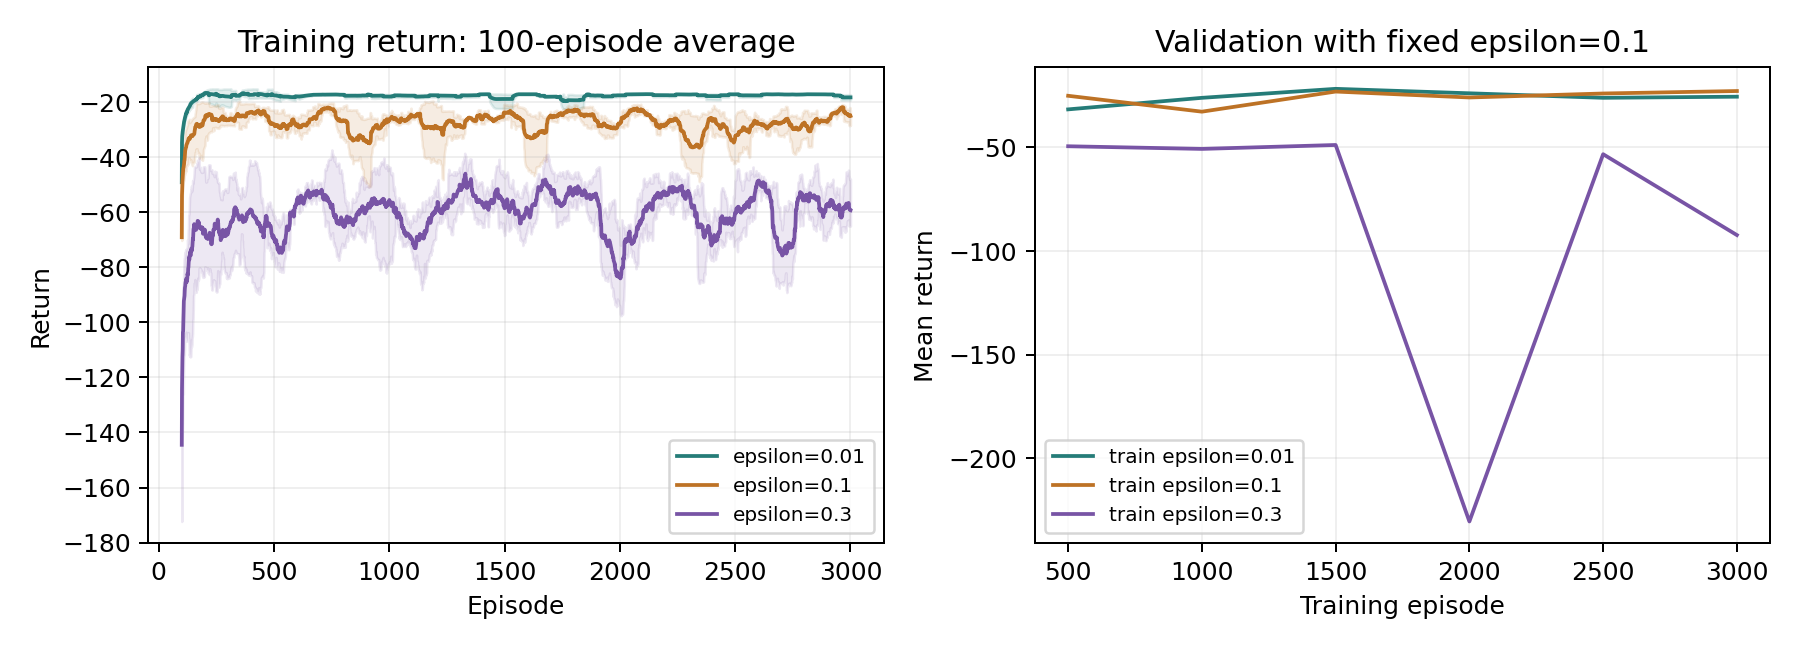

In [3]:
from IPython.display import display, Image
display(Image(filename="results/learning_curves.png"))

## Final evaluation
Selection uses validation seeds starting at 10000; final evaluation uses seeds starting at 20000 and an independent action generator. The environment has a fixed start and deterministic movement: repeated greedy episodes follow the same route. They do not represent 300 distinct tasks. The exploratory and random policies produce varied trajectories.

In [4]:
print("Selected training epsilon:",summary["selected_training_epsilon"])
for policy in ["greedy","exploratory","random"]:
    print(policy,summary[policy])
q=np.load("results/q_table.npy")
assert q.shape==(48,4) and np.isfinite(q).all()
print("Q-table shape:",q.shape)

Selected training epsilon: 0.1
greedy {'mean_return': -17.0, 'return_std': 0.0, 'success_rate': 1.0, 'mean_steps': 17.0, 'mean_cliff_falls': 0.0, 'episodes': 300, 'evaluation_epsilon': 0.0, 'random_policy': False, 'seed': 20000}
exploratory {'mean_return': -25.14666666666667, 'return_std': 22.50734154968855, 'success_rate': 1.0, 'mean_steps': 20.526666666666667, 'mean_cliff_falls': 0.04666666666666667, 'episodes': 300, 'evaluation_epsilon': 0.1, 'random_policy': False, 'seed': 20000}
random {'mean_return': -4926.196666666667, 'return_std': 1265.959410388577, 'success_rate': 0.08666666666666667, 'mean_steps': 482.08666666666664, 'mean_cliff_falls': 44.89, 'episodes': 300, 'evaluation_epsilon': 0.0, 'random_policy': True, 'seed': 20000}
Q-table shape: (48, 4)


## Learned route and successful animation

{'success': True, 'steps': 17, 'return': -17, 'cliff_falls': 0, 'states': [36, 24, 12, 13, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 23, 35, 47], 'seed': 2026}


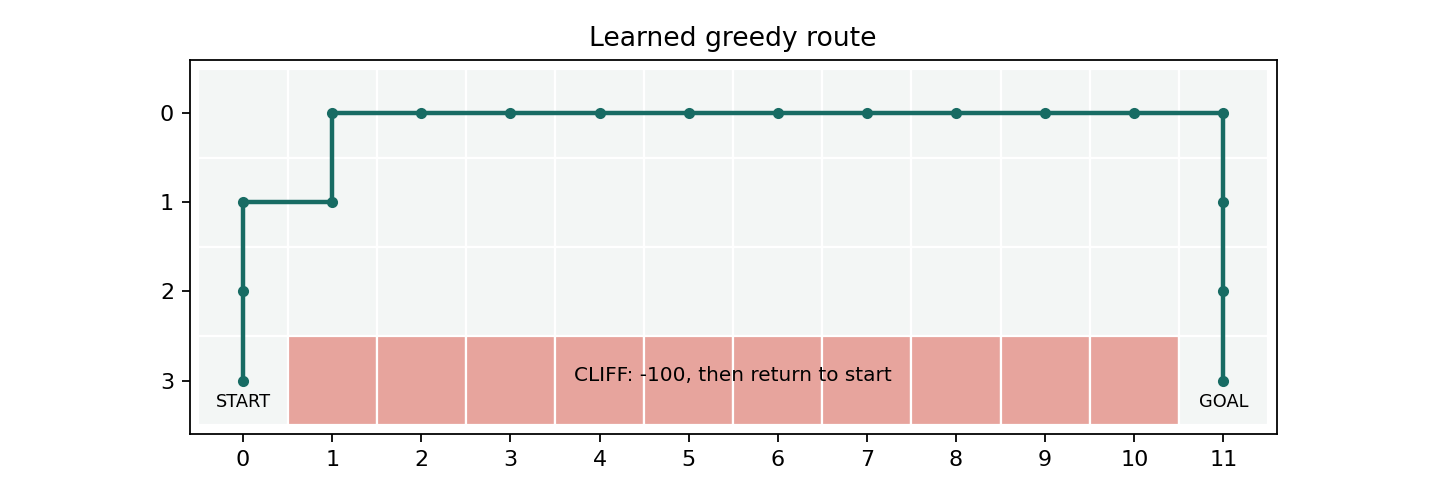

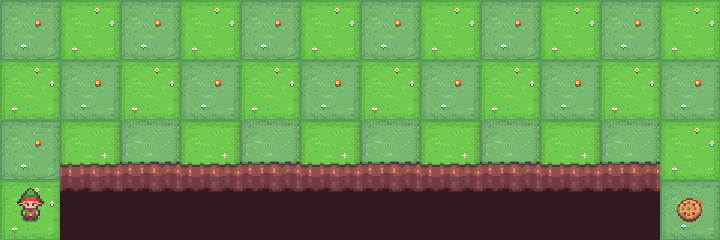

In [5]:
display(Image(filename="results/policy_route.png"))
display(Image(filename="results/trained_agent.gif"))
print(summary["demo"])

## Discussion
A large cliff penalty encourages routes that reduce risky exploratory falls. Training returns and greedy returns differ because exploration continues during learning. SARSA estimates the value of its behavior policy; switching to greedy evaluation changes that policy. Results apply to this fixed deterministic grid, not unseen maps.

Reference: https://gymnasium.farama.org/v1.2.3/environments/toy_text/cliff_walking/